<div align="center">

# Introducción a la manipulación y visualización de datos con Python

### Grupos de Estudio Autónomo (GEA) · Facultad de Ingeniería · Universidad Nacional de Colombia - Sede Bogotá

</div>

---

## Actividad 6 · Introducción a Matplotlib

> **Duración estimada:** 15 minutos  
> **Meta de este módulo:** Crear gráficas básicas (histograma y dispersión) y aprender a etiquetarlas.

## Ver los datos, no solo leerlos

Una tabla de números es difícil de interpretar de un vistazo. Las **gráficas** nos permiten
ver patrones, tendencias y relaciones al instante. **Matplotlib** es la librería fundamental
de visualización en Python; nos da control total sobre cada elemento del gráfico.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/housing.csv")
print("Dataset listo para graficar:", df.shape)

Dataset listo para graficar: (20640, 10)


### 1. Un histograma: ¿cómo se distribuyen los valores?

Un **histograma** muestra cómo se reparten los valores de una variable numérica: agrupa los datos
en intervalos ("bins") y cuenta cuántos caen en cada uno. Veamos la distribución del valor de vivienda:

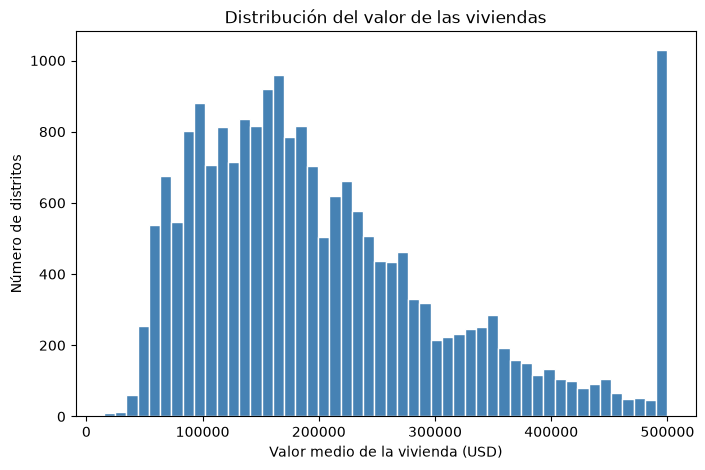

In [2]:
plt.figure(figsize=(8, 5))
plt.hist(df["median_house_value"], bins=50, color="steelblue", edgecolor="white")
plt.title("Distribución del valor de las viviendas")
plt.xlabel("Valor medio de la vivienda (USD)")
plt.ylabel("Número de distritos")
plt.show()

**¿Qué observamos?** La mayoría de los valores se concentran por debajo de los 300.000 USD.
También hay un "pico" sospechoso en el extremo derecho (500.001): es un **tope artificial** del
dataset, donde todos los valores muy altos se recortaron a ese número. ¡Estas cosas solo se notan
al graficar!

### 2. Un gráfico de dispersión: ¿hay relación entre dos variables?

Un **gráfico de dispersión** (scatter) coloca un punto por cada fila usando dos variables numéricas
(una en cada eje). Es ideal para ver si dos variables están **relacionadas**. Respondamos nuestra
**pregunta 1**:

> *¿El ingreso de una zona se relaciona con el valor de sus viviendas?*

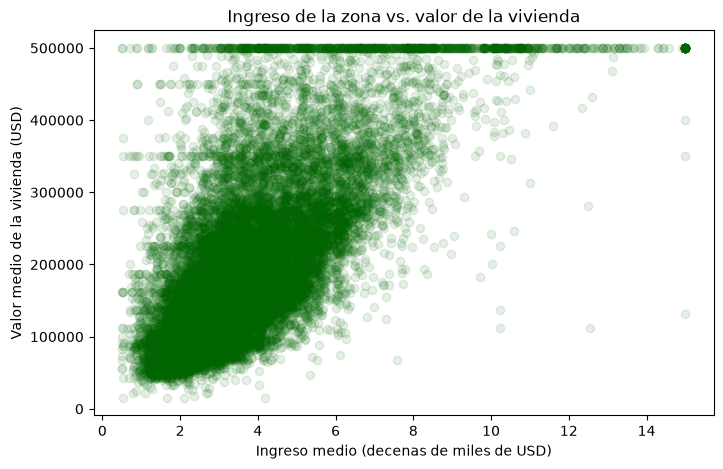

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(df["median_income"], df["median_house_value"],
            alpha=0.1, color="darkgreen")
plt.title("Ingreso de la zona vs. valor de la vivienda")
plt.xlabel("Ingreso medio (decenas de miles de USD)")
plt.ylabel("Valor medio de la vivienda (USD)")
plt.show()

**¿Qué observamos?** Aunque hay mucha dispersión, se ve una **tendencia ascendente**:
a mayor ingreso de la zona, mayor tiende a ser el valor de las viviendas. Usamos `alpha=0.1`
(transparencia) para que las zonas con muchos puntos se vean más oscuras.

### 3. Los elementos de una gráfica

Fíjate que en las gráficas anteriores siempre agregamos:

- `plt.title(...)` → un **título**.
- `plt.xlabel(...)` y `plt.ylabel(...)` → nombres a los **ejes**.
- `plt.legend(...)` → una **leyenda** (cuando hay varias series; lo vemos abajo).

Una gráfica sin títulos ni ejes etiquetados es casi inútil: nadie sabe qué está mirando.

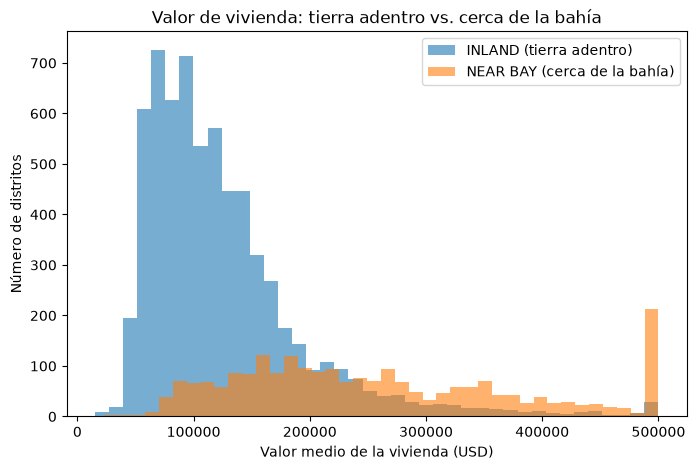

In [4]:
# Ejemplo con leyenda: comparar dos grupos en el mismo gráfico
inland = df[df["ocean_proximity"] == "INLAND"]
cerca  = df[df["ocean_proximity"] == "NEAR BAY"]

plt.figure(figsize=(8, 5))
plt.hist(inland["median_house_value"], bins=40, alpha=0.6, label="INLAND (tierra adentro)")
plt.hist(cerca["median_house_value"],  bins=40, alpha=0.6, label="NEAR BAY (cerca de la bahía)")
plt.title("Valor de vivienda: tierra adentro vs. cerca de la bahía")
plt.xlabel("Valor medio de la vivienda (USD)")
plt.ylabel("Número de distritos")
plt.legend()   # <- muestra la leyenda con las etiquetas 'label'
plt.show()

Este gráfico ya insinúa la respuesta a la pregunta 2: las viviendas cerca de la bahía
tienden a valer más que las de tierra adentro.

### 4. Bonus: el mapa escondido en los datos

Nuestro dataset tiene dos columnas que aún no hemos usado: `longitude` y `latitude`. ¿Qué pasa si
las ponemos en un scatter y **coloreamos cada punto según el valor de la vivienda**?
Ejecuta la celda y mira lo que aparece.

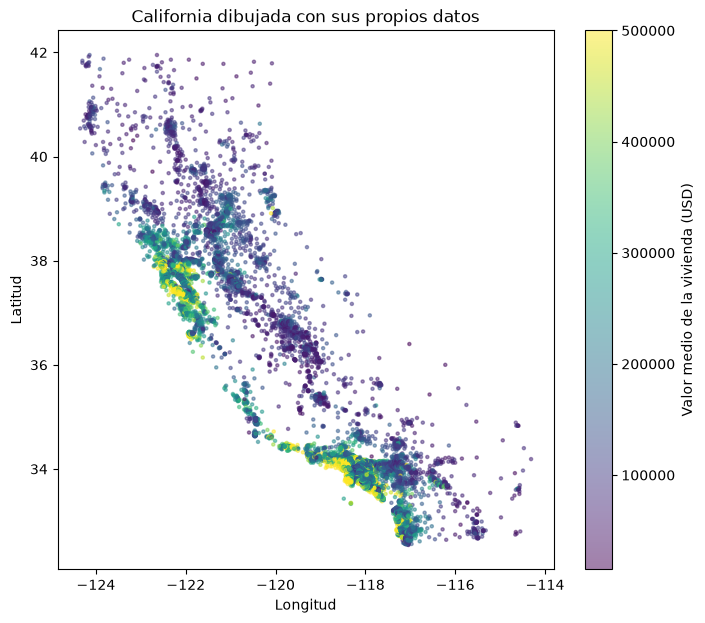

In [5]:
plt.figure(figsize=(8, 7))
plt.scatter(df["longitude"], df["latitude"],
            c=df["median_house_value"],   # el color depende del valor de la vivienda
            cmap="viridis", s=5, alpha=0.5)
plt.colorbar(label="Valor medio de la vivienda (USD)")
plt.title("California dibujada con sus propios datos")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()

**¿Qué observamos?** ¡Aparece el mapa de California! No descargamos ningún mapa: son solo los
20.640 distritos ubicados por sus coordenadas. Los puntos amarillos (viviendas más caras) se
concentran en la **costa**, sobre todo alrededor de San Francisco y Los Ángeles, mientras que el
interior es mayoritariamente morado. Es otra evidencia a favor de la pregunta 2.

Lo nuevo aquí: `c=` colorea los puntos según una variable, `cmap` elige la paleta de colores y
`plt.colorbar()` agrega la escala para poder leerla.

---
### Ya sabes hacer histogramas y dispersión con Matplotlib

Ahora veremos **Seaborn**, que hace gráficas estadísticas más bonitas con menos código.

**Siguiente:** [`07_seaborn.ipynb`](07_seaborn.ipynb)